## Phase 6: GenAI review analysis

# Review-theme analysis: what are customers actually complaining about?

**Why this analysis:** The statistics showed that late delivery explains only about a third of bad reviews. Two-thirds come from orders that arrived on time. The numbers can't say *why*, but the review text can.

**Approach (three layers)**
1. Count common words to see what customers talk about
2. Keyword rules to tag every comment with one or more themes
3. A free LLM (Gemini) to find themes the rules missed, summarize each theme, and translate examples

**Scope:** 1-2 star reviews with a written comment. Reviews are in Portuguese.

**Step 1: Load the complaints**

In [3]:
import pandas as pd
import numpy as np
import re 
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r"C:\Users\Gafoo\OneDrive\Documents\GitHub\Olist-Customer-Experience-Analytics\notebooks\data\clean_orders.csv")

df.head()

,order_id,customer_unique_id,customer_state,customer_city,customer_zip_code_prefix,seller_id,seller_state,seller_zip_code_prefix,order_status,order_purchase_timestamp,...,purchase_hour,is_weekend,approval_hours,price_per_item,seller_prior_late_rate,seller_prior_late_rate_cnt,seller_prior_low_rate,seller_prior_low_rate_cnt,prior_orders,is_repeat_customer
0,ec7a019261fce44180373d45b442d78f,f7b981e8a280e455ac3cbe0d5d171bd1,PR,curitiba,80030,48efc9d94a9834137efd9ea76b065a38,PR,81130.0,delivered,2017-01-05 11:56:06,...,11,0,0.236389,10.9,NaN,0.0,NaN,0.0,0,0
1,b95a0a8bd30aece4e94e81f0591249d8,83e7958a94bd7f74a9414d8782f87628,PR,curitiba,80030,48efc9d94a9834137efd9ea76b065a38,PR,81130.0,delivered,2017-01-05 12:01:20,...,12,0,39.571389,10.9,NaN,0.0,NaN,0.0,0,0
2,38bcb524e1c38c2c1b60600a80fc8999,728e4a7d0db4845270091ded0923c71f,PR,curitiba,80540,48efc9d94a9834137efd9ea76b065a38,PR,81130.0,delivered,2017-01-05 12:06:36,...,12,0,39.646111,2.9,NaN,0.0,NaN,0.0,0,0
3,7a18a504c1a4b32d883e68de2e1a7db0,728e4a7d0db4845270091ded0923c71f,PR,curitiba,80540,48efc9d94a9834137efd9ea76b065a38,PR,81130.0,delivered,2017-01-05 12:09:08,...,12,0,39.583333,7.9,NaN,0.0,NaN,0.0,1,1
4,6acecf438369055d9243e121045cca74,728e4a7d0db4845270091ded0923c71f,PR,curitiba,80540,48efc9d94a9834137efd9ea76b065a38,PR,81130.0,delivered,2017-01-05 12:11:23,...,12,0,39.545556,9.9,NaN,0.0,NaN,0.0,2,1


In [5]:
bad = df[df.low_review == 1]                                  # 1-2 star reviews
txt = bad[bad.review_comment_message.notna()].copy()          # ...that have a comment

print("Bad reviews:", len(bad))
print("With a written comment:", len(txt), f"({len(txt)/len(bad):.0%})")

Bad reviews: 12228
With a written comment: 9194 (75%)


## Step 1: How many complaints can we read?

| | Count |
|---|---|
| Bad reviews (1-2 stars) | 12,228 |
| Of those, with a written comment | **9,194 (75%)** |

**Why it matters:** We can only analyze the 75% who wrote something. Customers who write may be angrier or more articulate than those who don't, so the themes describe commenters, not every unhappy customer. This is a limitation.

**Text cleaning:** I lowercased the text and removed accents so "não" and "nao" match. Reviews are not translated at this stage; the keyword rules work on Portuguese.

Write the percentage down. Customers who write comments may differ from those who don’t, and that’s a limitation to mention.

Normalize the text (lowercase, no accents) so that “não” and “nao” match:

In [6]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s).lower())
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", s)

txt["clean"] = txt.review_comment_message.map(norm)
txt.review_comment_message.sample(15, random_state=1).tolist()

['A loja lannister é referência na entrega de seus produtos sempre comprei e recebo muito antes do prazo, mas esse parceiro, nãorecomendo.',
 'Bonita, pratica, porém a tampa da churrasqueira é mais pesada que o corpo e como a trava que para a tampa não funciona com o peso ela tompa, as alças da grelha vieram amassadas e tambem são fracas',
 'demora na entrega (ainda nao chegou fora do prazo)',
 'A entrega foi rápida mas o produto é de péssima qualidade .\r\nJá se rasgou no primeiro soco\r\n',
 'Estou aguardando o envio do "Manual" do produto comprado.',
 'Relógio com Defeito',
 'Gostei do produto, mas veio com a numeração em algarismo Romano errada. O número 4 está escrito como IIII.',
 'Não posso avaliar, não sei oque houve !',
 'N recebi o produto ainda, o prazo era pra ate o dia 8 e hoge é 10, na espera',
 'Esse remédio faz parte do tratamento que estou fazendo e ja vai fazer um mês que eu pedi e nada!!! \r\nEu quero respostas ou o meu dinheiro de volta! ',
 'A bolsa de cozimento rá

Read those 15 reviews. You don’t need to speak Portuguese. Paste a few into any free translator. Seeing real complaints first makes everything below easier to explain.

**Step 2: Discover what people talk about**

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

stop = ["de","a","o","que","e","do","da","em","um","uma","para","com","nao","os","as","no","na",
        "por","mais","foi","se","me","eu","meu","minha","mas","ao","dos","das","ja","so","pra",
        "produto","comprei","compra","recebi","ainda","muito","como","ate","tem","veio","pedido"]

cv = CountVectorizer(ngram_range=(1, 2), min_df=30, stop_words=stop)
counts = cv.fit_transform(txt.clean)
top = (pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
         .sort_values(ascending=False).head(40))
print(top)

entregue      1132
entrega       1108
chegou        1035
estou          793
prazo          734
esta           635
loja           612
dia            607
agora          533
apenas         521
dois           472
produtos       464
porem          446
pois           435
sem            430
qualidade      430
lannister      428
site           428
nada           428
quero          411
outro          401
mesmo          398
contato        381
nem            358
era            349
aguardando     342
tive           328
dias           321
fiz            320
duas           313
correios       309
momento        307
diferente      306
nota           303
ser            300
recomendo      296
paguei         285
ou             282
pedi           279
quando         277
dtype: int64


## Step 2: What do customers talk about most?

I counted the most frequent words and word pairs after removing filler words.

| Portuguese | English | Count |
|---|---|---|
| entregue / entrega / chegou | delivered / delivery / arrived | about 1,100 each |
| prazo | deadline | 734 |
| qualidade | quality | 430 |
| contato | contact | 381 |
| aguardando | waiting | 342 |
| correios | post office | 309 |
| dois / duas / apenas | two / only | 470 / 310 / 520 |
| diferente | different | 306 |

**What it tells us:** Delivery words dominate. Words like "apenas" (only) and "dois" (two) hint at orders where only part arrived. "Correios" (post office) shows up often, which the first themes did not cover. These clues shaped the theme list.

Translate the top words and bigrams. You’ll see clusters like delivery words (entrega, prazo, atraso), wrong or missing item words (errado, faltou), and seller or refund words (vendedor, devolucao). These become your themes.

**Step 3: Tag themes with simple rules**

Each theme is a list of Portuguese word starts. A review can have more than one theme.

no_theme                    30.6
Never arrived               23.6
Late delivery               14.1
Defective/poor quality      10.8
Seller/customer service      9.9
Missing/incomplete items     9.9
Refund/return                9.1
Wrong product                8.2
Misleading listing           5.1
Damaged in transit           4.7
dtype: float64


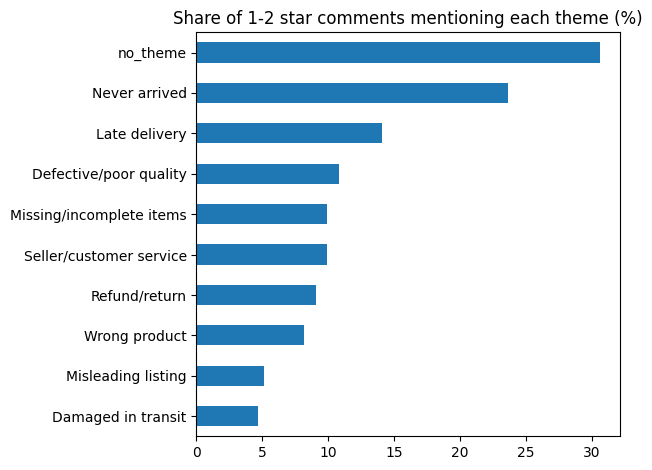

In [8]:
themes = {
 "Never arrived":           ["nao recebi", "nao chegou", "nunca chegou", "nao foi entregue", "ainda nao chegou"],
 "Late delivery":           ["atras", "demor", "prazo", "previsao"],
 "Wrong product":           ["errad", "diferent", "trocad", "outro produto", "nao e o que"],
 "Missing/incomplete items":["falt", "incomplet", "so veio", "veio so", "apenas um", "somente um"],
 "Defective/poor quality":  ["defeit", "nao funciona", "qualidade", "pessim", "falsific", "parou de funcionar"],
 "Damaged in transit":      ["quebrad", "quebrou", "danificad", "amassad", "avariad", "embalagem"],
 "Seller/customer service": ["vendedor", "atendimento", "contato", "resposta", "respondeu", "sac", "ninguem"],
 "Refund/return":           ["devol", "reembols", "estorn", "dinheiro de volta", "cancel"],
 "Misleading listing":      ["enganosa", "anuncio", "descricao", "foto", "tamanho"],
}

patterns = {t: re.compile(r"\b(?:" + "|".join(k) + ")") for t, k in themes.items()}
for t, p in patterns.items():
    txt[t] = txt.clean.map(lambda s: int(bool(p.search(s))))

theme_cols = list(themes)
txt["no_theme"] = (txt[theme_cols].sum(axis=1) == 0).astype(int)

share = (txt[theme_cols + ["no_theme"]].mean() * 100).round(1).sort_values(ascending=False)
print(share)
share.sort_values().plot(kind="barh", title="Share of 1-2 star comments mentioning each theme (%)")
plt.tight_layout(); plt.savefig("images/11_theme_share.png", dpi=150)

## Step 3: Tagging complaints with keyword rules

Each theme is a set of Portuguese keywords. A review can match several themes, so shares add up to more than 100%.

| Theme | % of complaints |
|---|---|
| **Unclassified** | **30.6%** |
| Never arrived | 23.6% |
| Late delivery | 14.1% |
| Defective / poor quality | 10.8% |
| Seller / customer service | 9.9% |
| Missing / incomplete items | 9.9% |
| Refund / return | 9.1% |
| Wrong product | 8.2% |
| Misleading listing | 5.1% |
| Damaged in transit | 4.7% |

**Known limitations of these rules**
- 30.6% of comments match no theme, which is above my 25% target. Gemini's analysis of a sample of those (Step 6) shows they are mostly partial orders, post-office pickup and wrong colour/size.
- Some keywords over-match. For example, "falta de respeito" (lack of respect) is tagged as missing items, and "antes do prazo" (before the deadline) is tagged as late.
- "Never arrived" is probably overstated, because it also catches partial and wrong-item orders.
- Rules can't understand negation or sarcasm.

**How I handled it:** I treat the shares as approximate and look at the *pattern* (which themes dominate late vs on-time orders) rather than exact percentages. The unclassified reviews were analyzed separately with an LLM.

**Step 4: The key insight, delivery complaints vs everything else**

This links the text to your statistics. Compare late and on-time orders:

In [9]:
by_late = (txt.groupby("is_late")[theme_cols + ["no_theme"]].mean().T * 100).round(1)
by_late.columns = ["On-time orders", "Late orders"]
print(by_late.sort_values("On-time orders", ascending=False))
print("\nComments from on-time orders:", (txt.is_late == 0).sum(), "| late:", (txt.is_late == 1).sum())

                          On-time orders  Late orders
no_theme                            34.0         22.7
Defective/poor quality              13.7          4.2
Missing/incomplete items            12.5          3.8
Never arrived                       12.5         49.7
Wrong product                       11.0          1.6
Refund/return                       10.1          6.6
Seller/customer service              9.4         10.9
Late delivery                        8.4         27.3
Misleading listing                   7.0          0.7
Damaged in transit                   6.4          0.8

Comments from on-time orders: 6449 | late: 2745


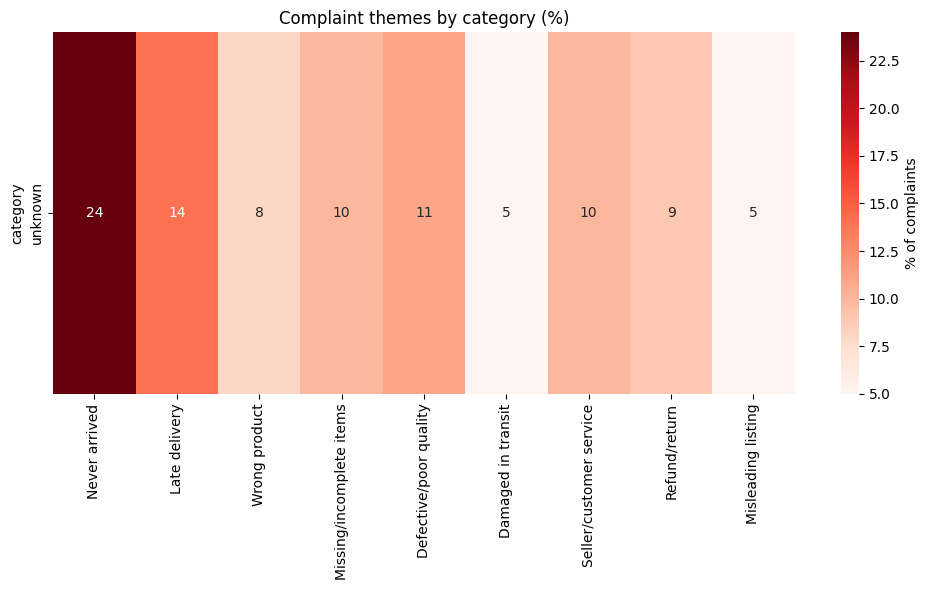

In [10]:
top_cats = txt.category.value_counts()
top_cats = top_cats[top_cats >= 150].index          # lower to 100 if you get too few
cat = (txt[txt.category.isin(top_cats)].groupby("category")[theme_cols].mean() * 100).round(0)

plt.figure(figsize=(10, 6))
sns.heatmap(cat, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of complaints"})
plt.title("Complaint themes by category (%)")
plt.tight_layout(); plt.savefig("images/12_theme_by_category.png", dpi=150)

## Step 4: What do late and on-time customers complain about? [v2: update the numbers]

| | Comments |
|---|---|
| From on-time orders | 6,449 (70%) |
| From late orders | 2,745 (30%) |

**Version 1 results (% of comments with each theme)**

| Theme | On-time orders | Late orders |
|---|---|---|
| Never arrived | 12.5 | **49.7** |
| Late delivery | 8.4 | **27.3** |
| Defective / poor quality | **13.7** | 4.2 |
| Missing / incomplete items | **12.5** | 3.8 |
| Wrong product | **11.0** | 1.6 |
| Refund / return | **10.1** | 6.6 |
| Seller / customer service | 9.4 | 10.9 |
| Misleading listing | **7.0** | 0.7 |
| Damaged in transit | **6.4** | 0.8 |

**What it means:**
1. **Late orders** are about delivery: roughly half say the product never arrived and a quarter say it was late.
2. **On-time orders** have spread-out complaints: quality, missing items, wrong product and returns are each about 10-14%. These make up 70% of the comments and explain the other two-thirds of bad reviews.
3. **"Never arrived" appears even in on-time orders (12.5%).** Customers say the item didn't come, but the system recorded it as delivered on time. Gemini's summary also found "tracking falsely shows delivered". This points to carrier scan problems, not only slow shipping.

**Answer to the client:** Ops is partly right (delivery). But most bad reviews come from what is in the box and how well the seller delivers on the order, which shipping speed alone won't fix.

## Complaint themes by category [fill in after v2]

*(Chart: images/12_theme_by_category.png)*

**Top 3 patterns I see:**
1. [category]: mostly [theme]
2. [category]: mostly [theme]
3. [category]: mostly [theme]

**Business use:** Categories with different complaint types need different fixes, for example packing checks for multi-item categories and listing checks for decor and apparel.

**Step 5: Validate by reading (don’t skip this)**

In [11]:

rng = np.random.default_rng(42)
for t in theme_cols:
    sub = txt[txt[t] == 1]
    print(f"\n=== {t} ({len(sub)} reviews) ===")
    for r in sub.review_comment_message.sample(min(5, len(sub)), random_state=7):
        print("-", r[:200].replace("\n", " "))


=== Never arrived (2172 reviews) ===
- Não recebi meu produto
- A entrega está muuuuito atrasada e não recebi nenhum retorno a respeito.
- Compra efetuada em 12/03/2018, postada dois dias depois e até a presente data, com até agora 2 dias de atraso não recebi a mercadoria
- não recomendo, não recebi o produto que comprei mandaram outro produto e ninguém resolve, um lixo de loja, não comprem, um desrespeito com o consumidor eu nunca mais vou comprar nesta loja.
 Acionarei a justiça comum caso a lannister não resolva. 

=== Late delivery (1293 reviews) ===
- Nao entregam no prazo!
- Não é possível tanta falta de atenção uma demora tremenda para receber o produto pra quando chegar vim errado e agora o q faço ???
- Bom produto com um bom preço, mas demorou pra postar a mercadoria nos correios (+10 dias), vencendo assim o prazo de entregra, que era para o dia 21/12. Deve levar mais mais 7 dias pra chegar ainda...
- Gostei do produto chegou antes do prazo, mas fiquei triste pq eu tinha feit

## Step 5: How accurate are the keyword rules?

I printed 5 random reviews per theme, read each one (translating where needed), and checked whether it truly belonged to its theme.

| Theme | Checked | Correct | Main error found |
|---|---|---|---|
| Never arrived | 4 | 2 | "não recebi" also matched "didn't receive a reply" and "received the wrong item" |
| Late delivery | 5 | 4 | "antes do prazo" (arrived before the deadline) matched as late |
| Wrong product | 5 | 4 | A fake watch that differed from the photo is a listing problem |
| Missing items | 5 | 3 | "falta de respeito" (lack of respect) matched "falt" |
| Defective / poor quality | 2 | 2 | none seen |
| Misleading listing | 4 | 3 | "tamanho" matched a damaged item with the wrong size |
| **Total** | **25** | **18** | **about 72% accurate** |

**What I learned**
- Short keywords ("falt", "prazo", "nao recebi") over-match, because the same words appear in other contexts.
- "Never arrived" is the weakest theme (2 of 4 correct), so its share is probably overstated.
- Themes overlap: a review can truly be about two things (late *and* wrong item).

**What I did about it:** I did not change the rules. I treat the percentages as approximate and focus on the *pattern* (which themes dominate late vs on-time orders), because the same rules apply to both groups. A small sample (25 reviews) means this accuracy figure is itself rough.

**Next step if time allowed:** tighten the keywords (for example, replace "falt" with "faltou/faltando"), exclude "antes do prazo", and re-check.

**Step 7: Save results for Excel and the memo**

In [21]:
out = pd.DataFrame({
    "theme": share.index,
    "pct_of_complaints": share.values,
}).merge(by_late.reset_index().rename(columns={"index": "theme"}), on="theme", how="left")
out.to_csv("data/theme_summary.csv", index=False)
cat.to_csv("data/theme_by_category.csv")

# 2-3 example reviews per theme, for the Excel report
examples = (txt.melt(id_vars=["order_id", "review_comment_message"], value_vars=theme_cols,
                     var_name="theme", value_name="hit").query("hit == 1")
               .groupby("theme").sample(3, random_state=5, replace=True)
               .drop_duplicates(["theme", "order_id"])[["theme", "review_comment_message"]])
examples.to_csv("data/theme_examples_pt.csv", index=False)

**Step 6: Use a free LLM to discover missing themes and translate**

In [12]:
pip install google-genai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Google renames and retires models often, so the code asks Google which models your key can use instead of hardcoding a name that may have expired.

**Connect and pick a working model**

In [13]:
import os, time, json, re
import pandas as pd
from google import genai
from google.genai import types

# Enter your Gemini API key here
API_KEY = "AQ.Ab8RN6JY3N8JTg7gZw8Qo0s1ByT5YbxKNLUXPiaC17VIwy2APw"

# Connect to Gemini
client = genai.Client(api_key=API_KEY)

# List models that can generate text
available = [
    m.name.replace("models/", "")
    for m in client.models.list()
    if "generateContent" in (m.supported_actions or [])
]

flash = [
    m for m in available
    if "flash" in m.lower() and "lite" not in m.lower()
]

print("Available Flash models:", flash)



Available Flash models: ['gemini-2.5-flash', 'gemini-2.5-flash-image', 'gemini-3.1-flash-image', 'gemini-3.5-flash', 'gemini-omni-flash-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash']


In [14]:
MODEL = "gemini-3.8-flash"       # or type a name from the list, e.g. "gemini-2.5-flash"
print("Using:", MODEL)

Using: gemini-3.8-flash


**A safe helper function**

In [15]:
def ask(prompt, json_mode=False, retries=4):
    cfg = types.GenerateContentConfig(
        temperature=0.2,                                   # low = more consistent, less creative
        response_mime_type="application/json" if json_mode else "text/plain")
    for attempt in range(retries):
        try:
            return client.models.generate_content(model=MODEL, contents=prompt, config=cfg).text
        except Exception as e:
            wait = 15 * (attempt + 1)
            print(f"  error: {str(e)[:120]} ... retrying in {wait}s")
            time.sleep(wait)
    return None

# Quick test
print(ask("Translate to English: 'O produto chegou quebrado e o vendedor não respondeu.'"))

"The product arrived broken and the seller did not respond." 

*(Alternative, more casual/common for reviews: "The product arrived broken and the seller hasn't responded.")*


**Part 4: Summarize each theme**

This continues from Step 3, where txt and theme_cols already exist.

In [16]:
def summarize_theme(theme, reviews):
    joined = "\n".join(f"- {r[:300]}" for r in reviews)
    prompt = f"""These are Portuguese 1-2 star reviews from a Brazilian online marketplace,
tagged with the theme '{theme}'.

Reply in English using exactly this format:
SUMMARY: (2 sentences on what customers complain about)
SUB-ISSUES: (3 short bullets)
EXAMPLES: (3 representative reviews translated into English, as bullets)
ACTION: (one practical action for the business)

Only use what appears in the reviews. Do not invent details.

Reviews:
{joined}"""
    return ask(prompt)

summaries = {}
for t in theme_cols:
    sub = txt[txt[t] == 1].review_comment_message.str.replace("\n", " ")
    sample = sub.sample(min(60, len(sub)), random_state=3).tolist()
    summaries[t] = summarize_theme(t, sample)
    print(f"\n### {t}  ({len(sub)} reviews)\n{summaries[t]}")
    time.sleep(6)           # stay under free-tier limits

with open("data/theme_summaries.json", "w", encoding="utf-8") as f:
    json.dump(summaries, f, ensure_ascii=False, indent=2)


### Never arrived  (2172 reviews)
SUMMARY: Customers complain that their purchases failed to arrive within the promised delivery deadlines, with several orders arriving only partially or not at all. Furthermore, they express frustration that tracking systems falsely mark orders as delivered, while customer support remains unresponsive or unable to provide updates and process refund requests.

SUB-ISSUES:
- Shipments severely delayed past the estimated date or missing entirely.
- Tracking status falsely showing the order as delivered.
- Incomplete orders and unresponsive customer service when resolving missing items or cancellations.

EXAMPLES:
- "I did not receive the product and it shows on tracking that it was already delivered, an absurdity."
- "I DID NOT RECEIVE MY PRODUCT, AND THE STORE DOES NOT EVEN KNOW WHERE THE PRODUCT IS. TERRIBLE CUSTOMER SERVICE AT Lannister'S SAC AS WELL."
- "One of the products that was requested was not delivered! The order placed was: glasses and the c

**Part 5: Discover themes your rules missed**

This is the most valuable part. It works on reviews with no_theme == 1, so it shows what your keyword rules couldn’t see.

In [18]:
untagged = txt[txt.no_theme == 1].review_comment_message.str.replace("\n", " ")
print("Untagged reviews:", len(untagged))

sample = untagged.sample(min(120, len(untagged)), random_state=1).tolist()
numbered = "\n".join(f"{i+1}. {r[:250]}" for i, r in enumerate(sample))

prompt = f"""These are Portuguese 1-2 star reviews from a Brazilian online marketplace that
my keyword rules could NOT classify.

Return JSON only, in this shape:
{{"themes": [{{"name": "short English name",
              "approx_share_pct": 0,
              "description": "one sentence",
              "portuguese_keywords": ["word1", "word2", "word3"],
              "example_english": ["translated review 1", "translated review 2"]}}]}}

Find 4 to 6 themes. Shares should add to about 100. Use only what is in the reviews.

Reviews:
{numbered}"""

raw = ask(prompt, json_mode=True)
new_themes = json.loads(re.sub(r"^```json|```$", "", raw.strip(), flags=re.M))["themes"]

for th in new_themes:
    print(f"\n{th['name']}  (~{th['approx_share_pct']}%)")
    print(" ", th["description"])
    print("  keywords:", th["portuguese_keywords"])
    print("  e.g.:", th["example_english"][0])

with open("data/new_themes.json", "w", encoding="utf-8") as f:
    json.dump(new_themes, f, ensure_ascii=False, indent=2)

Untagged reviews: 2814

Incomplete Delivery and Missing Items  (~30%)
  Customers who purchased multiple quantities or multi-item kits only received a partial order with items missing from the package.
  keywords: ['recebi apenas', 'só chegou', 'veio apenas', 'só mandaram', 'parciais']
  e.g.: I bought three products and only two arrived, what are you going to do.

Product Defects, Poor Quality, and Sizing Issues  (~25%)
  Buyers report products arriving damaged or broken, made of fragile or cheap materials, or having improper sizing and fit.
  keywords: ['frágil', 'pequeno', 'solda', 'descascando', 'não cabe', 'estourado']
  e.g.: The screen protector came with several circular marks, probably from manufacturing. I do not recommend the screen protector.

Delivery Delays and Non-Receipt  (~22%)
  Orders suffered extensive shipping delays, remained in transit for weeks, or were falsely marked as delivered without arriving.
  keywords: ['não entregue', 'aguardando a entrega', 'não recebi

In [19]:
themes["Seller cancelled order"] = ["cancelou", "cancelamento", "cancelaram"]

## Step 6: Using Gemini to find what the rules missed

I sent a sample of **120 of the 2,814 unclassified reviews** to Gemini and asked for themes, Portuguese keywords and translated examples. This was done on a sample, not all 40,000 reviews, which keeps it free, quick and checkable.

| Theme Gemini found | Share of the unclassified sample |
|---|---|
| Incomplete delivery / missing items | ~30% |
| Product defects, poor quality, sizing | ~25% |
| Delivery delays and non-receipt | ~22% |
| Wrong item or inferior model sent | ~13% |
| Forced post-office pickup despite paid delivery | ~10% |

**Important:** These shares are of the *unclassified* reviews only (about 31% of all comments), not of all complaints. For example, 30% of 31% is about 9% of all complaints.

**New themes I added to my rules:**
- **Partial orders:** "bought 3, received 2". This lines up with my regression model, where the number of items in an order was the second strongest driver of lower ratings.
- **Post-office pickup:** customers paid for home delivery but had to collect from the post office, a cost-and-promise problem the logistics partner can fix.

**Quality control:** Gemini's keywords and summaries were checked against reviews I read myself. I also reviewed the theme files for errors; for example, some "Damaged" reviews were really about missing items. LLM output can sound confident and still be wrong.

**Translation:** Example reviews were translated by Gemini in batches. A rate-limit error left some blanks, which I re-ran separately.

**Part 6: Translate examples for the Excel report**

This reads the example file from Step 7 and adds English translations.

In [ ]:
examples = pd.read_csv("data/theme_examples_pt.csv")
examples["review_comment_message"] = examples.review_comment_message.str.replace("\n", " ").str[:300]

translated = []
for start in range(0, len(examples), 20):
    chunk = examples.iloc[start:start + 20]
    numbered = "\n".join(f"{i}. {r}" for i, r in enumerate(chunk.review_comment_message))
    prompt = f"""Translate these Portuguese customer reviews into natural English.
Return JSON only: a list of strings in the same order, same count ({len(chunk)}).

{numbered}"""
    raw = ask(prompt, json_mode=True)
    try:
        translated += json.loads(re.sub(r"^```json|```$", "", raw.strip(), flags=re.M))
    except Exception:
        translated += [""] * len(chunk)       # keep alignment if a batch fails
    time.sleep(6)

examples["review_english"] = translated[:len(examples)]
examples.to_csv("data/theme_examples_en.csv", index=False)
print(examples[["theme", "review_english"]].head(10))


  error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and  ... retrying in 15s
  error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and  ... retrying in 30s
                    theme                                     review_english
0      Damaged in transit  The day before yesterday, I received a single ...
1      Damaged in transit  The watch is by no means unisex, it's feminine...
2      Damaged in transit  I ONLY RECEIVED ONE OF THE PRODUCTS, THE PEARL...
3  Defective/poor quality  I received a defective product; one side of th...
4  Defective/poor quality  terrible customer service merchandise arriving...
5  Defective/poor quality  Actually, I'm not speaking ill of the store it...
6           Late delivery  The final delivery deadline was April 27th, an...
7           Late delivery  With the estimated delivery time, you could ha...
8      

## Conclusion

**What the review text shows**

1. **Late orders (30% of comments):** complaints are about delivery. About half mention not receiving the order (49.7%) and about a quarter mention lateness (27.3%).
2. **On-time orders (70% of comments):** complaints are spread across several themes, each around 6-14%: defective or poor quality (13.7%), missing or incomplete items (12.5%), wrong product (11.0%), refund or return (10.1%) and misleading listing (7.0%). No single cause dominates, and most of these are not about shipping speed.
3. **This answers the open question from the statistics.** Two-thirds of bad reviews come from on-time orders, and the text shows they are mostly about what was in the box and whether it matched the order, not about delivery time.
4. **Missing or incomplete items is the second-largest theme among on-time orders, and my sample of unclassified reviews shows many are partial orders** ("bought 3, got 2"). This is consistent with the regression model, where orders with more items had lower predicted ratings. A likely explanation is multi-item orders shipped in separate packages. I did not test that directly.
5. **Gemini's analysis of a sample of unclassified reviews found a pattern my rules missed:** customers who paid for home delivery but had to collect the parcel from the post office. This is a sample-based finding. It is not in the keyword shares, so it is not measured across all reviews.

**Recommendations (draft)**
- Look into multi-item orders: ship them together, or tell customers up front when items come in separate packages
- Check pickup and "delivered" cases with the logistics partner before the renegotiation
- Focus pre-shipment checks (right item, colour, size, quantity) on the categories with the most complaints

**Limitations**
- Only 75% of bad reviews have a written comment, so the themes describe commenters, not every unhappy customer.
- The keyword rules were about 72% accurate in a hand check of 25 reviews. They over-match on words like "não recebi", "falt" and "prazo", so individual theme shares are approximate.
- 30.6% of comments matched no theme. A sample of these was analyzed with Gemini, but they are not counted in the theme shares.
- The most reliable result is the *comparison* between late and on-time orders, because the same rules were applied to both groups.
- LLM summaries and translations were checked on samples I read, not on every review.
- Themes show what customers say, not proven causes.